In [19]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [20]:
import os, sys, json
os.chdir("/content/drive/MyDrive/simuteh-2330511008/notebook")
sys.path.append("../src")

import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

PARAM = json.load(open("../hasil/param_praproses.json"))
label = pd.read_csv("../data/sintetis/label.csv")

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

print("Persiapan P6 siap! Direktori aktif:", os.getcwd())

Persiapan P6 siap! Direktori aktif: /content/drive/MyDrive/simuteh-2330511008/notebook


Kode 3.1 Mask daun awal dan bercak awal

         citra  IoU daun awal  komponen bercak awal  komponen acuan IoU bercak awal
0  teh_041.png          0.999                   165               8           0.558
1  teh_021.png          0.997                   195               3           0.099
2  teh_011.png          0.997                   152               0               -


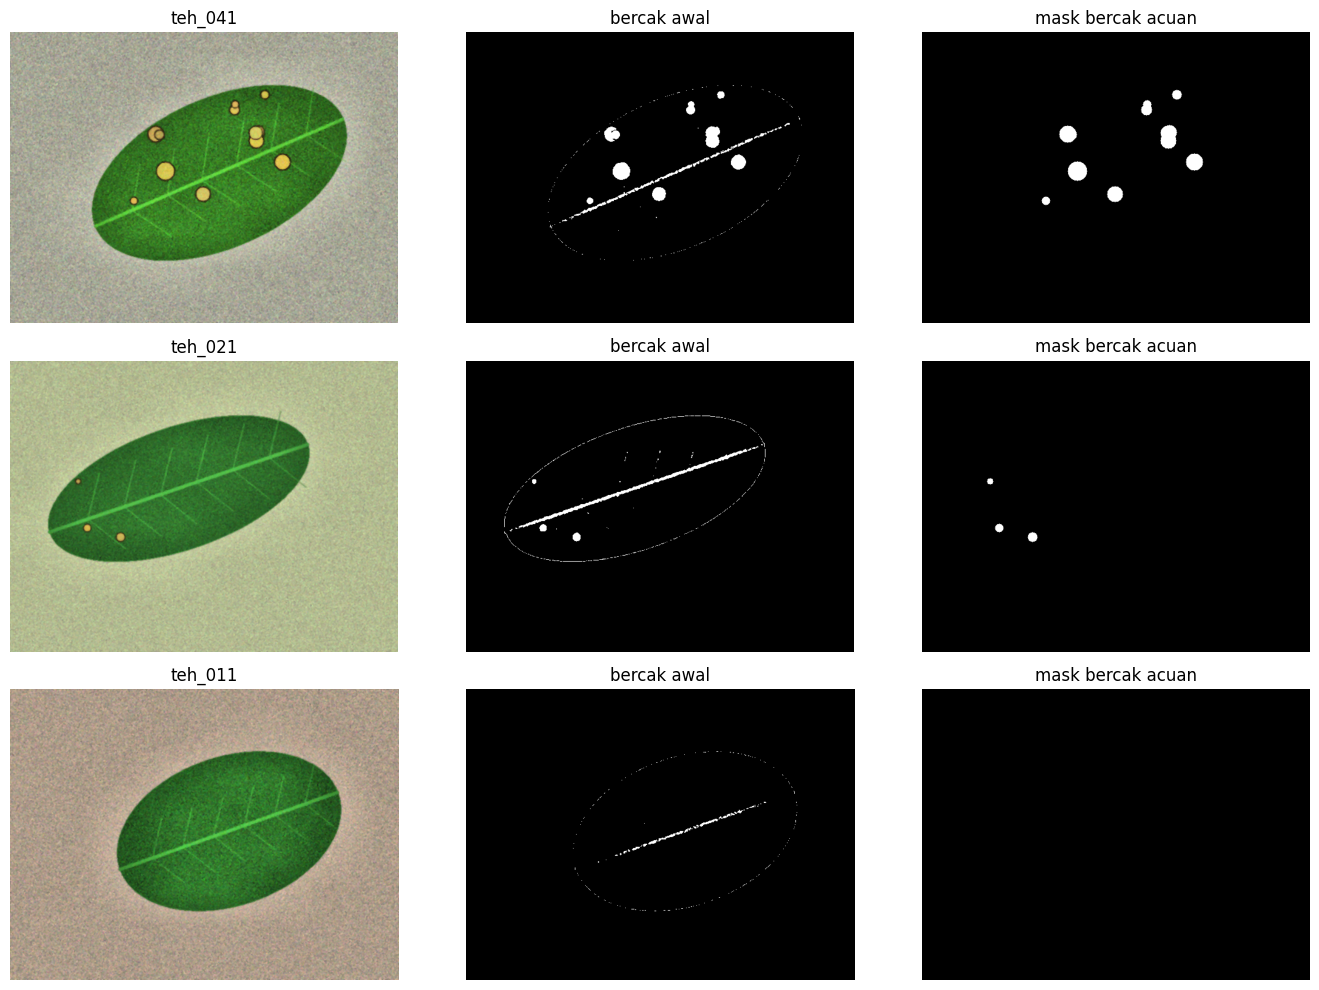

In [21]:
def jumlah_komponen(m, konek=8):
    return cv2.connectedComponents((m > 0).astype(np.uint8), connectivity=konek)[0] - 1

baris, panel, judul = [], [], []
for nama in ["teh_041.png", "teh_021.png", "teh_011.png"]:  # berat, ringan, sehat
    img, md, mb = muat(nama)
    pra = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra)
    b0 = bercak_awal(pra, m_daun, kanal=2, k=4.0)
    baris.append([nama, round(iou(m_daun, md), 3), jumlah_komponen(b0),
                  jumlah_komponen(mb), round(iou(b0, mb), 3) if mb.any() else "-"])
    panel += [pra, b0, mb]
    judul += [nama[:7], "bercak awal", "mask bercak acuan"]

print(pd.DataFrame(baris, columns=["citra", "IoU daun awal", "komponen bercak awal",
                                   "komponen acuan", "IoU bercak awal"]))
tampil(panel, judul, baris=3, ukuran=(14, 10))

Kode 3.2 Erosi, dilasi, opening, dan closing

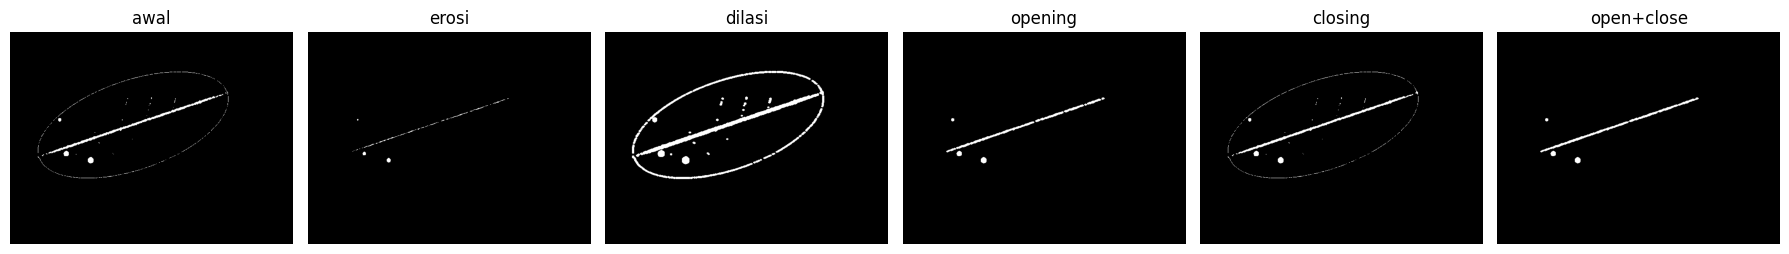

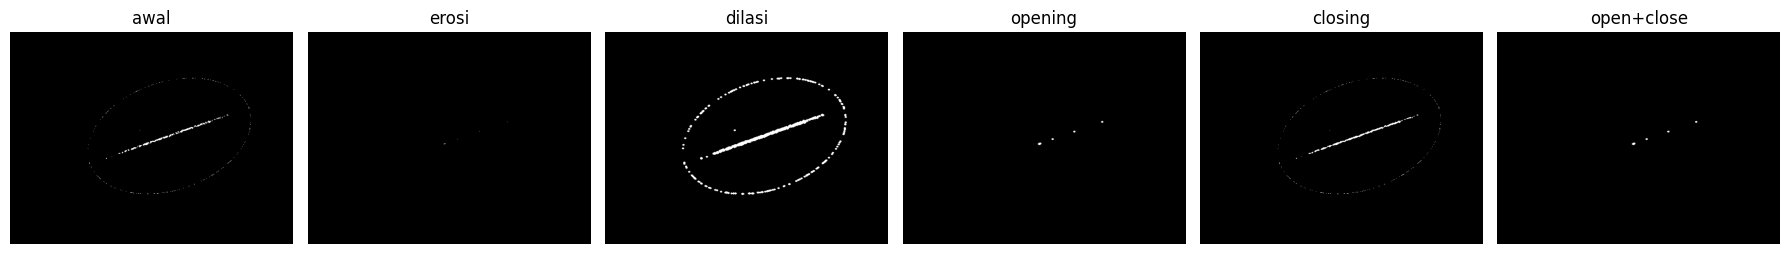

          citra     operasi  komponen  piksel    IoU
0   teh_021.png        awal       195    3070  0.099
1   teh_021.png       erosi        38     530  0.163
2   teh_021.png      dilasi        26    9533  0.045
3   teh_021.png     opening         8    2100  0.139
4   teh_021.png     closing       174    3166  0.096
5   teh_021.png  open+close         4    2142  0.136
6   teh_011.png        awal       152     854      -
7   teh_011.png       erosi         4       8      -
8   teh_011.png      dilasi        69    4241      -
9   teh_011.png     opening         4      85      -
10  teh_011.png     closing       136     980      -
11  teh_011.png  open+close         4      85      -


In [22]:
SE = lambda k, bentuk=cv2.MORPH_ELLIPSE: cv2.getStructuringElement(bentuk, (k,
k))

def operasi(b, se):
    return {"awal": b,
            "erosi": cv2.erode(b, se),
            "dilasi": cv2.dilate(b, se),
            "opening": cv2.morphologyEx(b, cv2.MORPH_OPEN, se),
            "closing": cv2.morphologyEx(b, cv2.MORPH_CLOSE, se),
            "open+close": cv2.morphologyEx(cv2.morphologyEx(b, cv2.MORPH_OPEN,
se), cv2.MORPH_CLOSE, se)}

baris = []
for nama in ["teh_021.png", "teh_011.png"]:
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    b0 = bercak_awal(pra_, mask_daun_awal(pra_))
    hasil = operasi(b0, SE(5))
    for nm, m in hasil.items():
        baris.append([nama, nm, jumlah_komponen(m), int((m > 0).sum()),
                      round(iou(m, mb), 3) if mb.any() else "-"])
    tampil(list(hasil.values()), list(hasil.keys()), ukuran=(18, 3));
plt.show()
print(pd.DataFrame(baris, columns=["citra", "operasi", "komponen", "piksel",
"IoU"]))

Kode 3.3 Eksperimen k, bentuk, dan ukuran SE

In [23]:
bentuk = {"persegi": cv2.MORPH_RECT, "elips": cv2.MORPH_ELLIPSE, "silang":
cv2.MORPH_CROSS}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    n_acuan = jumlah_komponen(mb)
    for k in [3, 4, 6]:
        b0 = bercak_awal(pra_, m_daun, k=k)
        for nb, kb in bentuk.items():
            for uk in [3, 5, 7]:
                se = SE(uk, kb)
                m = cv2.morphologyEx(cv2.morphologyEx(b0, cv2.MORPH_OPEN, se),
cv2.MORPH_CLOSE, se)
                baris.append([d.kelas, k, nb, uk, abs(jumlah_komponen(m) -
n_acuan),
                              iou(m, mb) if mb.any() else np.nan])
eks = pd.DataFrame(baris, columns=["kelas", "k", "bentuk", "ukuran",
"galat_jumlah", "IoU"])
print(eks.pivot_table(index=["k", "bentuk", "ukuran"], columns="kelas",
                      values=["galat_jumlah", "IoU"]).round(2))
eks.to_csv("../hasil/p6_eksperimen_se.csv", index=False)

                   IoU        galat_jumlah              
kelas            berat ringan        berat ringan  sehat
k bentuk  ukuran                                        
3 elips   3       0.60   0.15        19.70  26.55  18.40
          5       0.64   0.22         3.90   3.85   4.00
          7       0.69   0.44         1.30   2.10   3.50
  persegi 3       0.61   0.17         8.50   8.00   5.60
          5       0.66   0.30         2.50   4.40   4.25
          7       0.69   0.50         0.65   0.65   0.00
  silang  3       0.60   0.15        19.70  26.55  18.40
          5       0.64   0.21         7.95   6.65   6.50
          7       0.70   0.38         2.70   5.00   5.45
4 elips   3       0.66   0.24        15.10  11.40  12.55
          5       0.68   0.34         2.05   3.95   3.50
          7       0.68   0.51         0.80   0.80   0.65
  persegi 3       0.67   0.26         5.85   6.95   7.75
          5       0.68   0.46         0.85   1.85   2.50
          7       0.66   0.45  

Kode 3.4 Gradien morfologi dibandingkan dengan Canny

In [24]:
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    grad = cv2.morphologyEx(m_daun, cv2.MORPH_GRADIENT, SE(3)) # dilasi - erosi
    canny = tepi_canny(cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY))
    ad = tepi_acuan(md)
    baris.append([d.kondisi_cahaya, skor_tepi(grad, ad)[2], skor_tepi(canny, ad)[2]])

print(pd.DataFrame(baris, columns=["kondisi", "F1 gradien morfologi", "F1 Canny"]).groupby("kondisi").mean().round(3))

                F1 gradien morfologi  F1 Canny
kondisi                                       
bayangan                       0.888     0.705
gelap                          0.976     0.684
kontras_rendah                 0.263     0.873
normal                         0.988     0.686
terang                         0.953     0.695


3.6

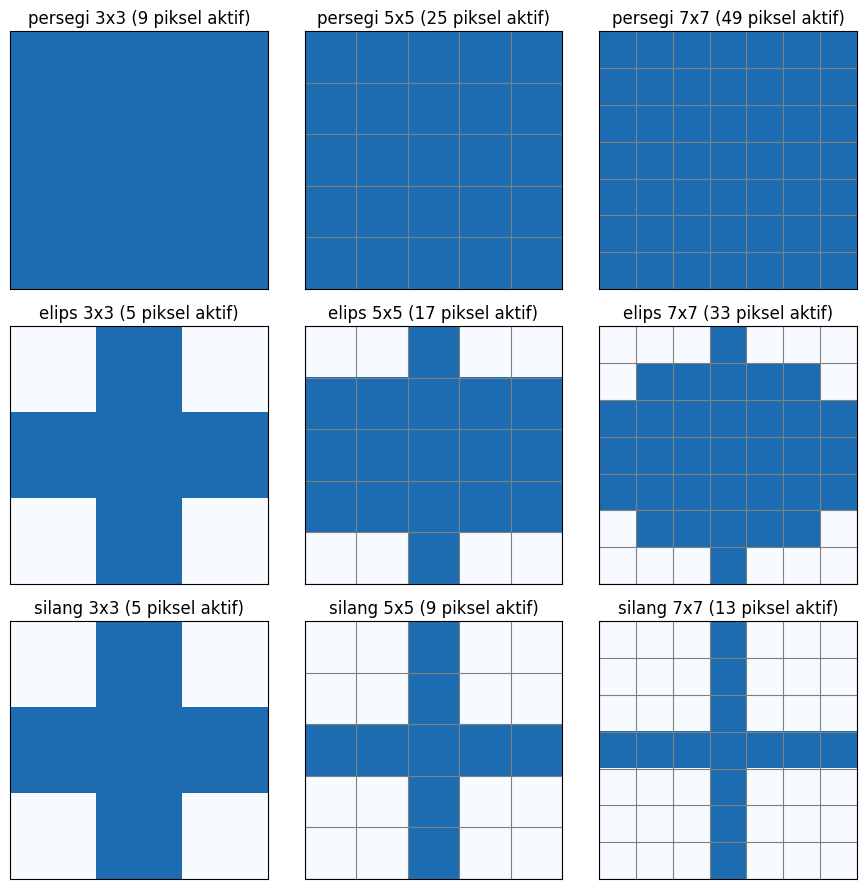

In [25]:
bentuk_se = {"persegi": cv2.MORPH_RECT, "elips": cv2.MORPH_ELLIPSE, "silang": cv2.MORPH_CROSS}
ukuran_se = [3, 5, 7]

plt.figure(figsize=(9, 9))
i = 1
for nb, kb in bentuk_se.items():
    for uk in ukuran_se:
        se = cv2.getStructuringElement(kb, (uk, uk))
        ax = plt.subplot(3, 3, i)
        ax.imshow(se, cmap="Blues", vmin=0, vmax=1.3)
        ax.set_xticks(np.arange(-0.5, uk, 1), minor=True)
        ax.set_yticks(np.arange(-0.5, uk, 1), minor=True)
        ax.grid(which="minor", color="gray", linewidth=0.8)
        ax.tick_params(which="both", bottom=False, left=False, labelbottom=False, labelleft=False)
        ax.set_title(f"{nb} {uk}x{uk} ({int(se.sum())} piksel aktif)")
        i += 1
plt.tight_layout()
plt.savefig("../hasil/p6_panel_se.png", dpi=150)
plt.show()

Kode 4.1 Komponen terhubung dan pengukuran setiap bercak

konektivitas 4: 19 komponen
konektivitas 8: 19 komponen
    label  luas_px  luas_mm2  keliling_px  kebulatan  rasio_aspek   cx   cy
0       1      111     21.25         36.7       1.03         1.10  419  103
1       2      243     46.51         60.3       0.84         1.50  370  125
2       3      692    132.45        107.5       0.75         1.52  406  172
3       4      455     87.09         83.0       0.83         1.08  239  167
4       5       17      3.25         13.7       1.15         1.25  488  169
5       6       43      8.23         25.3       0.84         2.20  464  179
6       7      470     89.96         78.4       0.96         1.00  448  214
7       8      659    126.14         93.3       0.95         1.00  255  228
8       9       86     16.46         51.1       0.41         4.60  360  224
9      10       39      7.46         25.3       0.76         2.52  335  234
10     11       26      4.98         18.5       0.96         1.87  300  250
11     12       17      3.25    

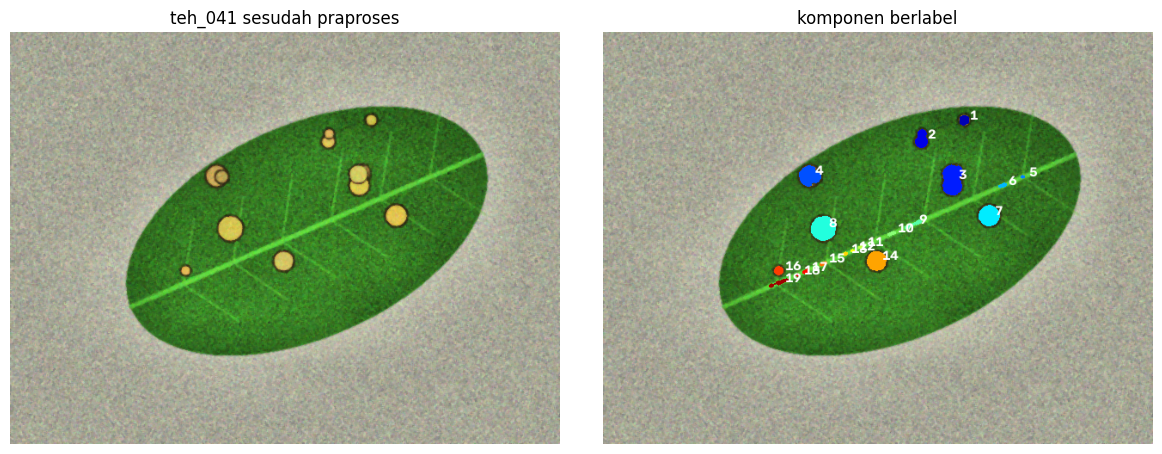

In [26]:
MM_PER_PX = 0.4375
# dari lembar hitung P2: Z = 200 mm, lebar kerja 640 px

def ukur_komponen(m, konek=8):
    n, lbl, st, cen = cv2.connectedComponentsWithStats((m > 0).astype(np.uint8), connectivity=konek)
    baris = []
    for i in range(1, n):
        kontur, _ = cv2.findContours((lbl == i).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        A = int(st[i, cv2.CC_STAT_AREA])
        keliling = cv2.arcLength(kontur[0], True)
        kebulatan = 0.0 if keliling == 0 else 4 * np.pi * A / keliling ** 2
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = max(w, h) / max(min(w, h), 1)
        baris.append([i, A, round(A * MM_PER_PX ** 2, 2), round(keliling, 1),
                      round(kebulatan, 2), round(rasio, 2), int(cen[i][0]), int(cen[i][1])])
    kolom = ["label", "luas_px", "luas_mm2", "keliling_px", "kebulatan", "rasio_aspek", "cx", "cy"]
    return pd.DataFrame(baris, columns=kolom), lbl

img, md, mb = muat("teh_041.png")
pra_ = praproses(img, PARAM)
m_daun = mask_daun_awal(pra_)
bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)), cv2.MORPH_CLOSE, SE(5))

for konek in [4, 8]:
    print(f"konektivitas {konek}: {jumlah_komponen(bersih, konek)} komponen")
tabel_kom, lbl = ukur_komponen(bersih)
print(tabel_kom)

warna = cv2.applyColorMap((lbl * (255 // max(lbl.max(), 1))).astype(np.uint8), cv2.COLORMAP_JET)
warna[lbl == 0] = pra_[lbl == 0]
for _, r in tabel_kom.iterrows():
    cv2.putText(warna, str(int(r.label)), (int(r.cx) + 8, int(r.cy)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)

tampil([pra_, warna], ["teh_041 sesudah praproses", "komponen berlabel"], ukuran=(12, 4.5))

Kode 4.2 Penyaringan komponen berdasarkan ukuran dan bentuk

In [27]:
def saring(m, luas_min=20, bulat_min=0.5, rasio_maks=1.8):
    tabel_k, lbl = ukur_komponen(m)
    lolos = tabel_k[(tabel_k.luas_px >= luas_min) & (tabel_k.kebulatan >=
bulat_min)
                    & (tabel_k.rasio_aspek <= rasio_maks)]
    return (np.isin(lbl, lolos.label.values) * 255).astype(np.uint8), lolos

aturan = {"tanpa saring": (0, 0, 99), "luas >= 20": (20, 0, 99),
          "luas + kebulatan": (20, 0.5, 99), "luas + kebulatan + rasio": (20,
0.5, 1.8)}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun),
cv2.MORPH_OPEN, SE(5)),
                              cv2.MORPH_CLOSE, SE(5))
    for nm, (a, b, r) in aturan.items():
        f, _ = saring(bersih, a, b, r)
        baris.append([d.kelas, nm, jumlah_komponen(f), jumlah_komponen(mb)])
uji = pd.DataFrame(baris, columns=["kelas", "aturan", "jumlah", "acuan"])
uji["galat"] = (uji.jumlah - uji.acuan).abs()
print(uji.pivot_table(index="aturan", columns="kelas",
values="galat").round(2))
print("Daun sehat yang masih memiliki bercak palsu:")
print(uji[uji.kelas == "sehat"].assign(palsu=lambda t: t.jumlah >
0).groupby("aturan").palsu.sum())

kelas                     berat  ringan  sehat
aturan                                        
luas + kebulatan           0.95    1.75   1.20
luas + kebulatan + rasio   0.60    1.05   0.55
luas >= 20                 1.30    2.65   2.20
tanpa saring               2.05    3.95   3.50
Daun sehat yang masih memiliki bercak palsu:
aturan
luas + kebulatan            11
luas + kebulatan + rasio     8
luas >= 20                  14
tanpa saring                15
Name: palsu, dtype: int64


In [28]:
# Hitung perbandingan luas total bercak hasil vs acuan pada teh_041
img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)
m_daun = mask_daun_awal(pra)
bersih = cv2.morphologyEx(
    cv2.morphologyEx(bercak_awal(pra, m_daun), cv2.MORPH_OPEN, SE(5)),
    cv2.MORPH_CLOSE, SE(5)
)
hasil_saring, _ = saring(bersih, luas_min=20, bulat_min=0.5, rasio_maks=1.8)

luas_hasil = int((hasil_saring > 0).sum())
luas_acuan = int((mb > 0).sum())
selisih_persen = ((luas_hasil - luas_acuan) / luas_acuan) * 100

print(f"Luas bercak hasil   : {luas_hasil} px")
print(f"Luas bercak acuan   : {luas_acuan} px")
print(f"Selisih persentase  : {selisih_persen:+.2f}%")

Luas bercak hasil   : 3159 px
Luas bercak acuan   : 4110 px
Selisih persentase  : -23.14%


Kode 5.1 Kerangka src/bercak.py

In [29]:
%%writefile ../src/bercak.py
"""bercak.py: analisis bercak SIMUTEH (dipakai ulang mulai P7)."""
import json
import cv2
import numpy as np
from utils_tepi import mask_daun_awal, bercak_awal

PARAM_BERCAK = {
    "kanal": 2,            # kanal terpilih (2 = R)
    "k": 4.0,              # ambang median + k x MAD
    "se_bentuk": "elips",  # "elips", "persegi", "silang"
    "se_open": 5,          # ukuran SE opening (0 = tidak dipakai)
    "se_close": 5,         # ukuran SE closing (0 = tidak dipakai)
    "luas_min": 20,        # piksel
    "bulat_min": 0.5,
    "rasio_maks": 1.8,
    "batas_ringan": 0.1,   # persen bercak minimum kelas Ringan
    "batas_berat": 2.0,    # persen bercak minimum kelas Berat
    "mm_per_px": 0.4375,
}
_BENTUK = {"elips": cv2.MORPH_ELLIPSE, "persegi": cv2.MORPH_RECT, "silang": cv2.MORPH_CROSS}


def _se(p, uk):
    return cv2.getStructuringElement(_BENTUK[p["se_bentuk"]], (uk, uk))


def bersihkan(biner, p):
    """Opening membuang titik derau dan potongan tipis; closing menutup celah."""
    # TODO 1: bila p["se_open"] > 0, lakukan opening dengan SE _se(p, p["se_open"])
    if p["se_open"] > 0:
        biner = cv2.morphologyEx(biner, cv2.MORPH_OPEN, _se(p, p["se_open"]))
    # TODO 2: bila p["se_close"] > 0, lakukan closing dengan SE _se(p, p["se_close"])
    if p["se_close"] > 0:
        biner = cv2.morphologyEx(biner, cv2.MORPH_CLOSE, _se(p, p["se_close"]))
    return biner


def ukur_dan_saring(biner, p):
    """Mengembalikan mask bercak tersaring dan daftar ukuran setiap bercak."""
    # TODO 3: label komponen terhubung (konektivitas 8) dengan cv2.connectedComponentsWithStats
    n, lbl, st, cen = cv2.connectedComponentsWithStats((biner > 0).astype(np.uint8), connectivity=8)
    keluar, daftar = np.zeros_like(biner), []
    mm_px = p["mm_per_px"]

    # TODO 4 & TODO 5: hitung ukuran tiap komponen, saring, dan catat ke daftar
    for i in range(1, n):
        A = int(st[i, cv2.CC_STAT_AREA])
        if A < p["luas_min"]:
            continue
        kontur, _ = cv2.findContours((lbl == i).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        if not kontur:
            continue
        keliling = cv2.arcLength(kontur[0], True)
        kebulatan = 0.0 if keliling == 0 else 4 * np.pi * A / (keliling ** 2)
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = max(w, h) / max(min(w, h), 1)

        if kebulatan >= p["bulat_min"] and rasio <= p["rasio_maks"]:
            keluar[lbl == i] = 255
            daftar.append({
                "label": len(daftar) + 1,
                "luas_px": A,
                "luas_mm2": round(A * (mm_px ** 2), 2),
                "keliling_px": round(float(keliling), 1),
                "kebulatan": round(float(kebulatan), 2),
                "rasio_aspek": round(float(rasio), 2),
                "cx": int(cen[i][0]),
                "cy": int(cen[i][1]),
            })
    return keluar, daftar


def analisis_daun(img_praproses, p=None):
    """Masukan: citra BGR hasil praproses. Keluaran: kamus hasil analisis."""
    p = {**PARAM_BERCAK, **(p or {})}
    m_daun = mask_daun_awal(img_praproses)
    biner = bercak_awal(img_praproses, m_daun, kanal=p["kanal"], k=p["k"])
    m_bercak, daftar = ukur_dan_saring(bersihkan(biner, p), p)

    # TODO 6: hitung persen bercak = luas bercak / luas daun x 100
    luas_daun = int((m_daun > 0).sum())
    luas_bercak = int((m_bercak > 0).sum())
    persen = 0.0 if luas_daun == 0 else (luas_bercak / luas_daun) * 100.0

    # TODO 7: tentukan kelas dengan batas_ringan dan batas_berat
    if persen >= p["batas_berat"]:
        kelas = "Bercak Berat"
    elif persen >= p["batas_ringan"]:
        kelas = "Bercak Ringan"
    else:
        kelas = "Sehat"

    return {
        "mask_daun": m_daun,
        "mask_bercak": m_bercak,
        "jumlah_bercak": len(daftar),
        "persen_bercak": round(float(persen), 3),
        "kelas": kelas,
        "bercak": daftar,
    }


def simpan_param(p, path="../hasil/param_bercak.json"):
    with open(path, "w") as f:
        json.dump({**PARAM_BERCAK, **p}, f, indent=2)

Overwriting ../src/bercak.py


Kode 5.2 Evaluasi modul bercak.py

=== RINGKASAN TABEL 12 ===
Galat absolut rerata persen bercak : 0.56
Korelasi persen prediksi vs acuan  : 0.971
Akurasi kelas                      : 0.883
Daun sehat dinilai berbercak       : 0
Daun berbercak dinilai sehat       : 3

=== MATRIKS KEKELIRUAN ===
prediksi       Bercak Berat  Bercak Ringan  Sehat
acuan                                            
Bercak Berat             16              4      0
Bercak Ringan             0             17      3
Sehat                     0              0     20

=== AKURASI PER KONDISI CAHAYA ===
kondisi
bayangan          0.92
gelap             0.92
kontras_rendah    0.75
normal            1.00
terang            0.83
Name: benar, dtype: float64


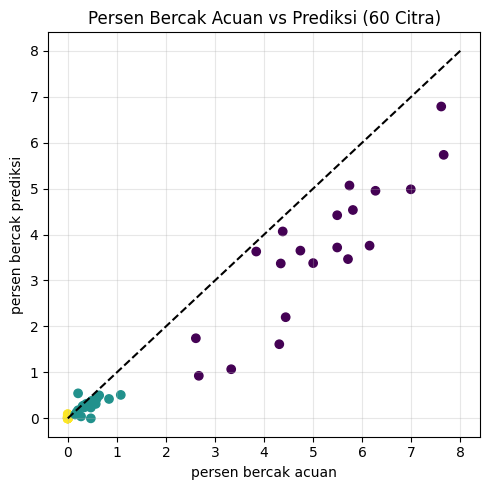


=== TOTAL CITRA SALAH KELAS: 7 ===


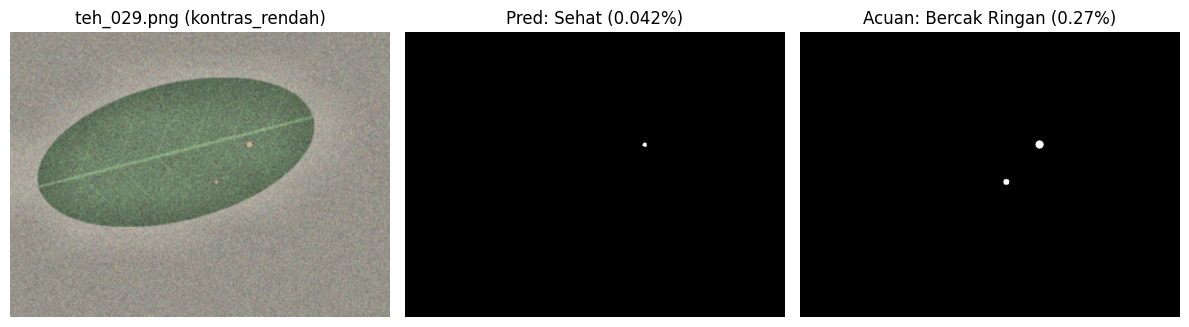

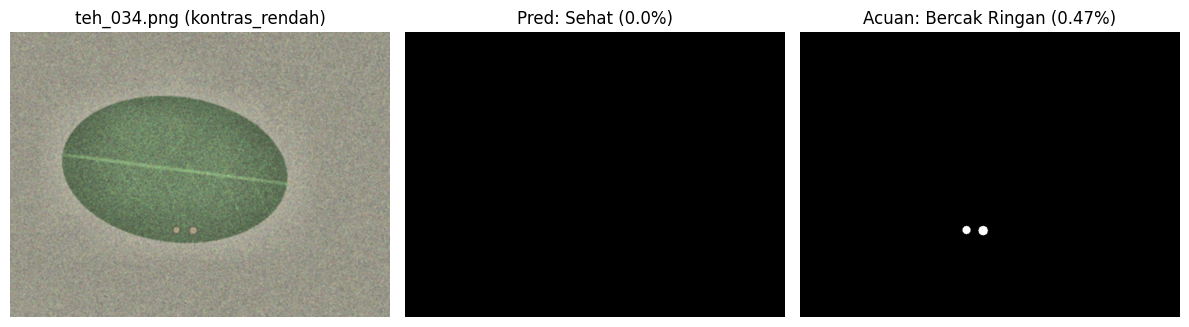

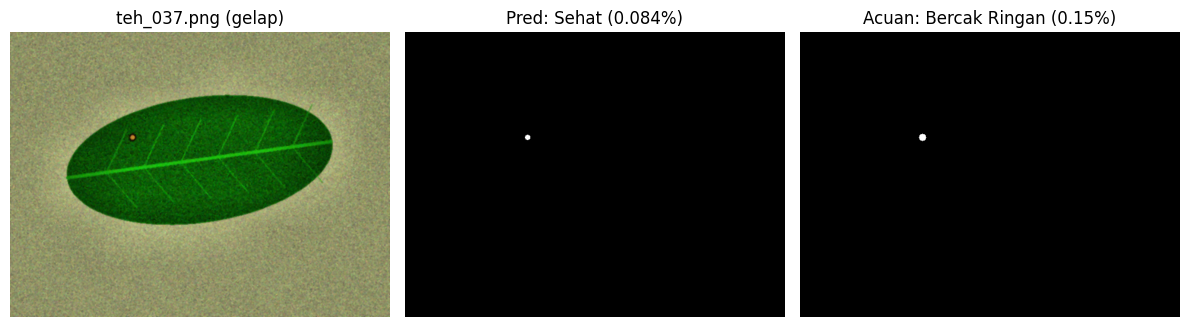

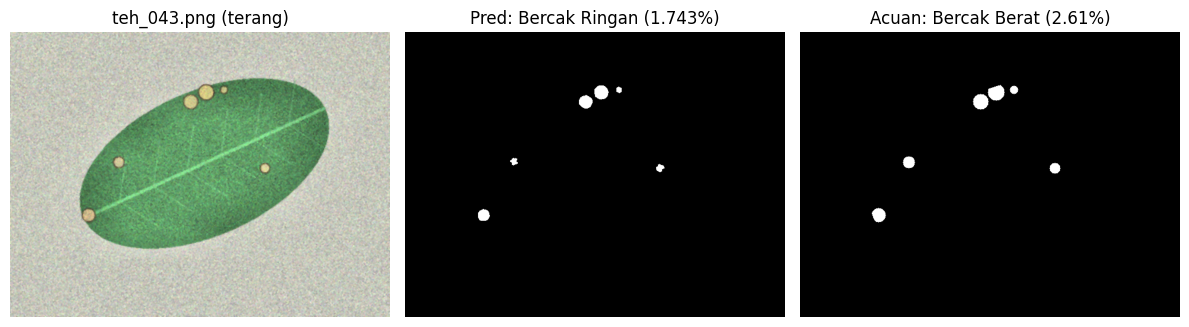

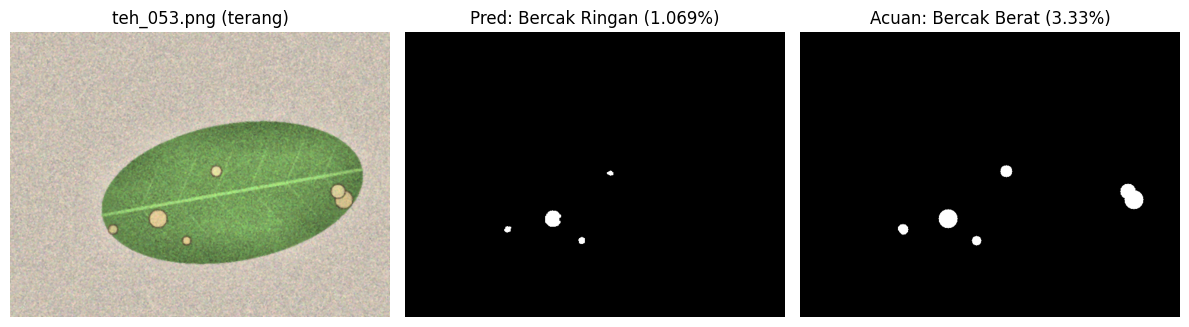

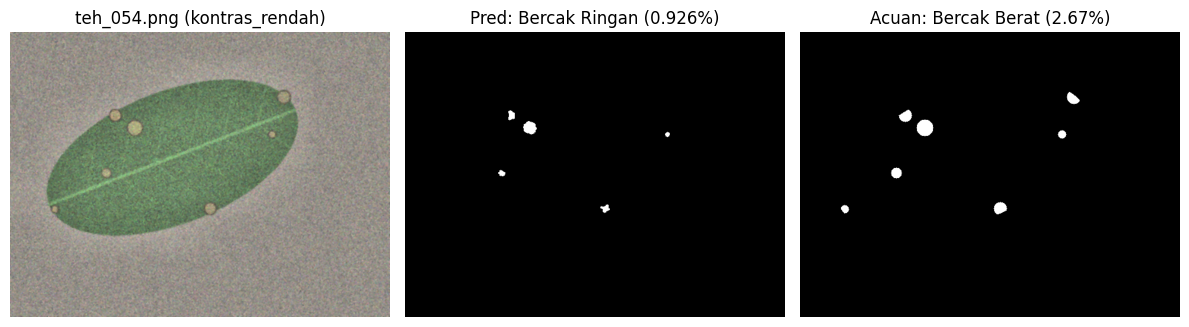

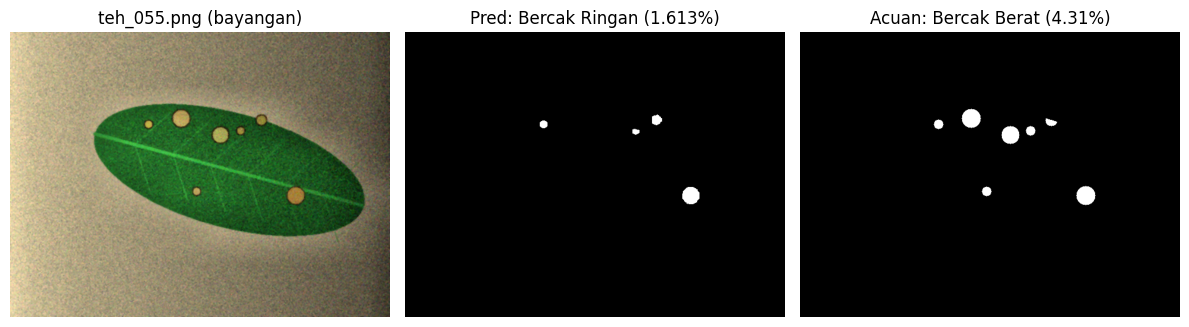

In [30]:
import importlib, bercak
importlib.reload(bercak)

PB = {}
bercak.simpan_param(PB)

baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    h = bercak.analisis_daun(praproses(img, PARAM), PB)
    baris.append([
        d.nama_file, d.kelas, d.kondisi_cahaya, d.persen_bercak,
        h["persen_bercak"], jumlah_komponen(mb), h["jumlah_bercak"], h["kelas"]
    ])

ev = pd.DataFrame(baris, columns=[
    "nama", "kelas", "kondisi", "persen_acuan",
    "persen_prediksi", "jumlah_acuan", "jumlah_prediksi", "kelas_prediksi"
])
ev["kelas_acuan"] = ev.kelas.map({
    "sehat": "Sehat",
    "ringan": "Bercak Ringan",
    "berat": "Bercak Berat"
})
ev.to_csv("../hasil/p6_evaluasi_bercak.csv", index=False)

print("=== RINGKASAN TABEL 12 ===")
print("Galat absolut rerata persen bercak :", (ev.persen_prediksi - ev.persen_acuan).abs().mean().round(3))
print("Korelasi persen prediksi vs acuan  :", ev[["persen_prediksi", "persen_acuan"]].corr().iloc[0, 1].round(3))
print("Akurasi kelas                      :", (ev.kelas_prediksi == ev.kelas_acuan).mean().round(3))
print("Daun sehat dinilai berbercak       :", ((ev.kelas_acuan == "Sehat") & (ev.kelas_prediksi != "Sehat")).sum())
print("Daun berbercak dinilai sehat       :", ((ev.kelas_acuan != "Sehat") & (ev.kelas_prediksi == "Sehat")).sum())

print("\n=== MATRIKS KEKELIRUAN ===")
print(pd.crosstab(ev.kelas_acuan, ev.kelas_prediksi, rownames=["acuan"], colnames=["prediksi"]))

print("\n=== AKURASI PER KONDISI CAHAYA ===")
print(ev.assign(benar=ev.kelas_prediksi == ev.kelas_acuan).groupby("kondisi").benar.mean().round(2))

plt.figure(figsize=(5, 5))
plt.scatter(ev.persen_acuan, ev.persen_prediksi, c=ev.kelas.astype("category").cat.codes)
plt.plot([0, 8], [0, 8], "k--")
plt.xlabel("persen bercak acuan")
plt.ylabel("persen bercak prediksi")
plt.title("Persen Bercak Acuan vs Prediksi (60 Citra)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("../hasil/p6_sebar_persen.png", dpi=150)
plt.show()

# --- LANGKAH 5.3: Citra yang salah kelas ---
salah = ev[ev["kelas_prediksi"] != ev["kelas_acuan"]]
print(f"\n=== TOTAL CITRA SALAH KELAS: {len(salah)} ===")
for _, r in salah.iterrows():
    img, md, mb = muat(r["nama"])
    pra = praproses(img, PARAM)
    h = bercak.analisis_daun(pra, PB)
    tampil(
        [pra, h["mask_bercak"], mb],
        [
            f"{r['nama']} ({r['kondisi']})",
            f"Pred: {r['kelas_prediksi']} ({r['persen_prediksi']}%)",
            f"Acuan: {r['kelas_acuan']} ({r['persen_acuan']}%)"
        ],
        ukuran=(12, 3.5)
    )